# Passo 3 – O que a árvore vê (variáveis)

Cada linha é um candle *t*. A árvore só pode usar o que já é conhecido **no fechamento de t**; o alvo é o retorno de *t → t+1* (em %), sem custo.

| Grupo | Variáveis | Intuição |
|---|---|---|
| lags | retorno do candle t, t−1, …, t−k+1 | continuidade ou reversão |
| forma | amplitude, corpo, posição do fechamento na barra | força de compra/venda no candle |
| volatilidade | desvio dos últimos 20 retornos; esse desvio relativo à sua média | mercado calmo × agitado |
| volume | volume / média dos últimos 20 candles | tem gente por trás do movimento? |
| contexto_dia | hora, retorno desde a abertura, distância da máxima e da mínima do dia | abertura, meio e fim do pregão são diferentes |

**Como avaliamos neste passo (simplificado de propósito):** uma RF *fixa* e moderada, treinada uma vez em todo o período de treino (10/2020–12/2023), prevendo 2024.
Candle × janela deslizante é o Passo 4 e hiperparâmetros o Passo 6 – aqui só queremos saber **quais variáveis carregam informação**.

RF usada: 300 árvores, profundidade máx. 6, folha mín. 0,5% das linhas, 50% das variáveis por divisão.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from sklearn.ensemble import RandomForestRegressor
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
CANDLES = [5, 15, 30, 60]

def rf_padrao(n_linhas):
    return RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=max(20, int(0.005 * n_linhas)),
                                 max_features=0.5, n_jobs=-1, random_state=42)

def preparar(m, n_lags=10):
    b = rz.adicionar_alvo(rz.reamostrar(win_1m, m))
    b, grupos = rz.criar_variaveis(b, n_lags)
    cols = sum(grupos.values(), [])
    b = b.dropna(subset=cols + ["ret_prox"])
    return b[b.index < rz.VALIDACAO[0]], rz.periodo(b, rz.VALIDACAO), grupos

def treinar_avaliar(tr, va, cols):
    rf = rf_padrao(len(tr)).fit(tr[cols], tr["ret_prox"])
    return rf, rf.predict(va[cols])

dados = {m: preparar(m) for m in CANDLES}
{m: (len(tr), len(va)) for m, (tr, va, _) in dados.items()}

{5: (72255, 26808), 15: (23692, 8769), 30: (11451, 4259), 60: (5336, 2004)}

## 3.1 Quantos lags? (só o passado do retorno)

In [2]:
res = {}
for m, (tr, va, g) in dados.items():
    for k in [3, 5, 10]:
        cols = [f"ret_lag{i}" for i in range(1, k + 1)]
        _, p = treinar_avaliar(tr, va, cols)
        res[(f"{m} min", f"{k} lags")] = rz.avaliar(p, va)
tab_lags = pd.DataFrame(res).T
tab_lags.round(3)

R² vs naive %  acerto direção %  ganho bruto pts/op  \
5 min  3 lags           0.011            50.903               0.859   
       5 lags           0.013            50.907               1.022   
       10 lags          0.004            50.342               0.628   
15 min 3 lags          -0.251            49.048              -4.423   
       5 lags          -0.142            49.234              -2.882   
       10 lags         -0.086            49.268              -2.375   
30 min 3 lags          -0.162            49.143              -2.787   
       5 lags          -0.166            51.095               3.496   
       10 lags         -0.170            51.023               0.855   
60 min 3 lags          -0.392            51.309              -2.767   
       5 lags          -0.202            51.712               7.138   
       10 lags         -0.170            50.453               1.634   

                t ganho bruto  ganho bruto 20% fortes  
5 min  3 lags           1.515                   2.383  
       5 lags           1.803                   3.331  
       10 lags          1.107                   3.806  
15 min 3 lags          -2.594                 -11.497  
       5 lags          -1.690                  -8.050  
       10 lags         -1.392                  -1.876  
30 min 3 lags          -0.810                  -0.029  
       5 lags           1.016                   1.133  
       10 lags          0.248                  -1.432  
60 min 3 lags          -0.404                 -16.883  
       5 lags           1.042                 -20.773  
       10 lags          0.239                 -15.012

## 3.2 Somando os grupos um a um

Partindo dos lags, acrescentamos um grupo por vez. Se uma linha melhora (R² sobe, ganho bruto sobe), o grupo ajuda.

In [3]:
N_LAGS = 5   # ajustar se 3.1 indicar outro valor
ordem = ["lags", "forma", "volatilidade", "volume", "contexto_dia"]
res, cols_por_etapa = {}, {}
for m, (tr, va, g) in dados.items():
    cols = []
    for grp in ordem:
        cols += [f"ret_lag{i}" for i in range(1, N_LAGS + 1)] if grp == "lags" else g[grp]
        _, p = treinar_avaliar(tr, va, cols)
        res[(f"{m} min", "+ " + grp)] = rz.avaliar(p, va)
tab_grupos = pd.DataFrame(res).T
tab_grupos.round(3)

R² vs naive %  acerto direção %  ganho bruto pts/op  \
5 min  + lags                  0.013            50.907               1.022   
       + forma                -0.004            51.352               1.290   
       + volatilidade         -0.011            51.079               0.939   
       + volume               -0.041            50.987               0.639   
       + contexto_dia         -0.032            51.052               0.629   
15 min + lags                 -0.142            49.234              -2.882   
       + forma                -0.070            49.489              -2.625   
       + volatilidade         -0.058            50.070              -0.954   
       + volume               -0.025            50.035              -0.757   
       + contexto_dia         -0.015            50.372              -0.424   
30 min + lags                 -0.166            51.095               3.496   
       + forma                -0.416            50.714               1.799   
       + volatilidade         -0.210            51.095               5.163   
       + volume               -0.161            51.238               4.088   
       + contexto_dia         -0.146            51.499               5.837   
60 min + lags                 -0.202            51.712               7.138   
       + forma                 0.069            52.971              10.102   
       + volatilidade         -0.417            51.511               2.178   
       + volume                0.278            52.216               7.937   
       + contexto_dia          0.492            52.266              12.927   

                       t ganho bruto  ganho bruto 20% fortes  
5 min  + lags                  1.803                   3.331  
       + forma                 2.276                   2.666  
       + volatilidade          1.658                   0.701  
       + volume                1.127                  -0.467  
       + contexto_dia          1.111                   1.033  
15 min + lags                 -1.690                  -8.050  
       + forma                -1.539                  -8.466  
       + volatilidade         -0.559                  -4.433  
       + volume               -0.444                  -0.921  
       + contexto_dia         -0.248                   4.504  
30 min + lags                  1.016                   1.133  
       + forma                 0.523                 -11.050  
       + volatilidade          1.500                 -11.543  
       + volume                1.188                  -8.468  
       + contexto_dia          1.696                  -0.974  
60 min + lags                  1.042                 -20.773  
       + forma                 1.476                  10.287  
       + volatilidade          0.318                 -20.112  
       + volume                1.159                  27.805  
       + contexto_dia          1.889                  34.165

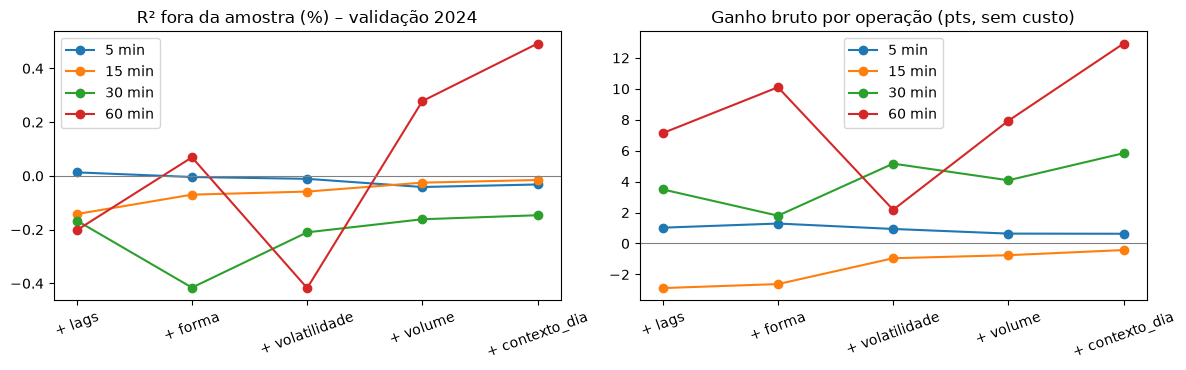

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for m in CANDLES:
    t = tab_grupos.loc[f"{m} min"]
    axs[0].plot(range(len(ordem)), t["R² vs naive %"], "o-", label=f"{m} min")
    axs[1].plot(range(len(ordem)), t["ganho bruto pts/op"], "o-", label=f"{m} min")
for a, tit in zip(axs, ["R² fora da amostra (%) – validação 2024", "Ganho bruto por operação (pts, sem custo)"]):
    a.set_xticks(range(len(ordem))); a.set_xticklabels(["+ " + o for o in ordem], rotation=20)
    a.axhline(0, color="gray", lw=.8); a.set_title(tit); a.legend()
plt.tight_layout(); plt.savefig("passo03_grupos.png", dpi=120); plt.show()

## 3.3 O que a árvore realmente usa: importância por permutação

Com o modelo completo, embaralhamos **um grupo de cada vez** na validação e medimos quanto o erro piora.
Se embaralhar um grupo não muda nada, a árvore não depende dele. (Mais honesto que a importância "de impureza" do sklearn, que favorece variáveis contínuas e é medida no treino.)

In [5]:
rng = np.random.default_rng(0)
imp = {}
for m, (tr, va, g) in dados.items():
    grupos = {"lags": [f"ret_lag{i}" for i in range(1, N_LAGS + 1)]} | {k: v for k, v in g.items() if k != "lags"}
    cols = sum(grupos.values(), [])
    rf, p = treinar_avaliar(tr, va, cols)
    y = va["ret_prox"].values
    eqm_base = np.mean((y - p) ** 2)
    linha = {}
    for nome, gcols in grupos.items():
        aumentos = []
        for _ in range(5):
            X = va[cols].copy()
            idx = rng.permutation(len(X))
            X[gcols] = X[gcols].values[idx]
            aumentos.append(np.mean((y - rf.predict(X)) ** 2) / eqm_base - 1)
        linha[nome] = 100 * np.mean(aumentos)       # % de aumento no erro
    imp[f"{m} min"] = linha
tab_imp = pd.DataFrame(imp)
tab_imp.round(4)

,5 min,15 min,30 min,60 min
lags,0.0132,-0.0668,0.2088,0.2349
forma,0.0348,-0.0181,-0.1135,0.0818
volatilidade,-0.0150,0.0137,0.2140,0.2114
volume,-0.0018,0.0540,0.3166,1.1807
contexto_dia,-0.0030,0.0241,-0.0662,0.1252


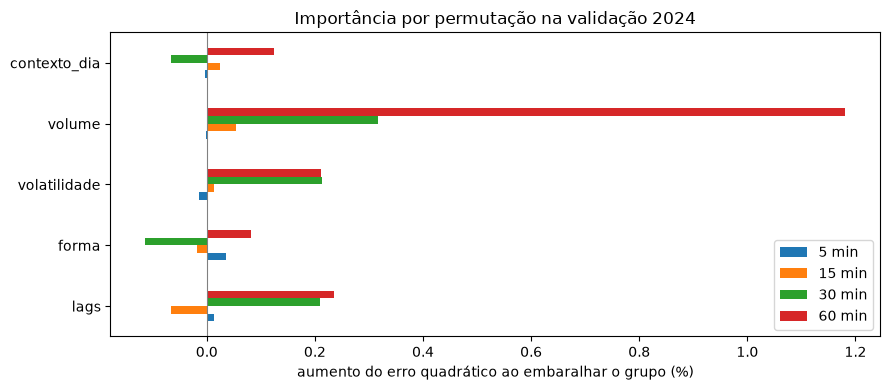

In [6]:
ax = tab_imp.plot.barh(figsize=(9, 4))
ax.set_xlabel("aumento do erro quadrático ao embaralhar o grupo (%)"); ax.axvline(0, color="gray", lw=.8)
ax.set_title("Importância por permutação na validação 2024")
plt.tight_layout(); plt.savefig("passo03_importancia.png", dpi=120); plt.show()

## Conclusões do Passo 3

1. **O sinal é fraco e ruidoso.** A maioria dos R² fica entre −0,4% e +0,5%, e trocar 3 por 5 lags chega a virar o ganho de −2,8 para +3,5 pts (30 min). Diferenças desse tamanho são, em boa parte, ruído: não dá para escolher variável olhando uma célula da tabela.
2. **Lags: 5 é um bom meio-termo.** Em 3 dos 4 candles, 5 lags ficou igual ou melhor que 3 e que 10. Mais lags não ajudou (mais variáveis = mais chance de a árvore decorar ruído).
3. **O conjunto completo é o melhor ou próximo do melhor em 15, 30 e 60 min.** No candle de 60 min ele chega a R² = +0,49% e ganho bruto de +12,9 pts/op (t = 1,9) – o único caso de R² claramente positivo. No de 5 min, lags + forma é o melhor (+1,3 pts/op, t = 2,3), mas esse ganho é pequeno perto do custo de 5 pts.
4. **Importância por permutação:** no candle de 60 min a árvore depende principalmente do **volume relativo** (embaralhá-lo piora o erro em 1,2%), seguido de lags e volatilidade. Nos candles curtos, nenhum grupo se destaca – coerente com o sinal quase nulo.

➡️ **Decisão:** seguir para o Passo 4 com **5 lags + todos os grupos** (17 variáveis). A RF lida bem com variáveis pouco úteis; se no Passo 6 alguma atrapalhar, cortamos lá.

⚠️ Aqui a RF foi treinada uma única vez em 2020–2023. No Passo 4 ela passa a ser re-treinada a cada trimestre com janela deslizante, que é o jeito realista de operar.
